
# V14 — Full 6-Month Timeline, 2-Month Walk-Forward Test, Temporal Safe RL

This version keeps **all rows** from the six-month CSV, including inactive/missing bars.

Missing bars are not dropped. They stay in sequence and the policy is forced to `0` contracts when a real current→next 30-minute transition is unavailable.

## Split clarification

A strict chronological 80/20 split of six months cannot mathematically give a two-month test:

\[
0.20 \times 6 \approx 1.2 \text{ months}
\]

So this notebook evaluates both:

1. **Strict chronological 80/20**, and
2. **July 13 → September 11 walk-forward**, which is ~61 calendar days.

In the long walk-forward test, the model trades each day unseen, then may learn from that completed day before the next day begins.

## Policy

- HMM supplies bullish/bearish/sideways direction.
- Require 4 consecutive directional tradable HMM bars.
- Causal time-of-day, weekday, and week-of-month performance priors.
- Historically bad time slots are excluded.
- Mandatory synthetic protective hedge on every futures position.
- Thesis-break exit if the signal deteriorates while the insured-loss budget is being consumed.
- A severe loss at an entry time triggers a cooldown for the next 2 opportunities at that same time.
- A Bayesian fitted-Q meta-controller can veto or downsize an otherwise valid expert trade.
- RL cannot invent direction; it is a safe residual layer.


In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge, BayesianRidge
from sklearn.preprocessing import StandardScaler

CSV_PATH = Path("C:/Users/Aadya Gupta/Desktop/Capstone/code_hmm/span10_predictions_every_30min_ALL_6_months.csv")

INITIAL_CAPITAL = 100_000.0
MAX_CONTRACTS = 4

HEDGE_FLOOR_BPS = 10.0
HEDGE_NET_COST_BPS = 1.0

PERSISTENCE_BARS = 4
MIN_SLOT_HISTORY = 2
SEVERE_LOSS_TRIGGER_FRACTION = 0.40
SLOT_COOLDOWN_OPPORTUNITIES = 2

OPPOSITE_EDGE_MIN_BPS = 0.25
OPPOSITE_EDGE_STRENGTHEN_RATIO = 1.10

BROKERAGE_RATE = 0.0003
BROKERAGE_CAP_RUPEES = 20.0
NSE_CURRENCY_FUT_TXN_RATE = 0.0000035
SEBI_TURNOVER_RATE = 10.0 / 10_000_000.0
NSE_IPFT_RATE = 0.05 / 100_000.0
GST_RATE = 0.18
STAMP_DUTY_BUY_RATE = 0.000001
FULL_SPREAD_BPS = 0.50
SLIPPAGE_BPS = 0.10

raw = pd.read_csv(CSV_PATH)
raw["timestamp"] = pd.to_datetime(raw["timestamp"])
raw["trading_date"] = pd.to_datetime(raw["trading_date"])

def prepare_timeline(raw_df):
    x = raw_df.copy()

    time_dt = pd.to_datetime(x["time"], format="%H:%M")
    x["slot"] = (time_dt.dt.hour * 2 + time_dt.dt.minute // 30 - 18).clip(0, 15)
    x["dow"] = x["trading_date"].dt.dayofweek
    x["dom"] = x["trading_date"].dt.day
    x["wom"] = ((x["dom"] - 1) // 7).clip(0, 4)
    x["month"] = x["trading_date"].dt.month

    probs = x[["p_bearish", "p_sideways", "p_bullish"]].copy().fillna(1/3)
    x[["p_bearish", "p_sideways", "p_bullish"]] = probs

    x["hmm_conf"] = probs.max(axis=1)
    x["hmm_entropy"] = -(probs * np.log(probs.clip(1e-8))).sum(axis=1)

    x["hdir"] = (
        x["predicted_situation_next_30min"]
        .map({"bullish": 1, "bearish": -1, "sideways": 0})
        .fillna(0)
        .astype(int)
    )

    x["tradable_transition"] = (
        (x["bar_traded"] == 1)
        & (x["next_bar_traded"] == 1)
        & x["real_next_move_bps"].notna()
    ).astype(int)

    for k in [1, 2, 3, 4]:
        x[f"lag{k}"] = (
            x.groupby("trading_date")["real_next_move_bps"]
            .shift(k)
            .fillna(0.0)
        )

    x["recent_mean"] = x[[f"lag{k}" for k in [1,2,3,4]]].mean(axis=1)
    x["recent_vol"] = x[[f"lag{k}" for k in [1,2,3,4]]].std(axis=1).fillna(0.0)

    streaks = []
    previous_date = None
    previous_dir = 0
    streak = 0

    for _, row in x.iterrows():
        if previous_date is None or row["trading_date"] != previous_date:
            previous_dir = 0
            streak = 0

        direction = int(row["hdir"])

        if row["tradable_transition"] == 1 and direction != 0:
            if direction == previous_dir:
                streak += 1
            else:
                previous_dir = direction
                streak = 1
        else:
            previous_dir = 0
            streak = 0

        streaks.append(streak)
        previous_date = row["trading_date"]

    x["hmm_streak"] = streaks
    x["bars_remaining"] = 15 - x["slot"]

    x["slot_sin"] = np.sin(2*np.pi*x["slot"]/16)
    x["slot_cos"] = np.cos(2*np.pi*x["slot"]/16)
    x["dow_sin"] = np.sin(2*np.pi*x["dow"]/5)
    x["dow_cos"] = np.cos(2*np.pi*x["dow"]/5)
    x["wom_sin"] = np.sin(2*np.pi*x["wom"]/5)
    x["wom_cos"] = np.cos(2*np.pi*x["wom"]/5)
    x["month_sin"] = np.sin(2*np.pi*x["month"]/12)
    x["month_cos"] = np.cos(2*np.pi*x["month"]/12)
    x["dom_sin"] = np.sin(2*np.pi*x["dom"]/31)
    x["dom_cos"] = np.cos(2*np.pi*x["dom"]/31)

    for c in [
        "edge_estimate_bps",
        "class_slot_prior", "class_dow_prior", "class_wom_prior",
        "class_time_prior",
        "class_slot_count", "class_dow_count", "class_wom_count",
    ]:
        x[c] = 0.0

    historical_indices = []

    for day in sorted(x["trading_date"].unique()):
        current_idx = x.index[x["trading_date"] == day]

        hist = x.loc[historical_indices] if historical_indices else x.iloc[:0]
        valid_hist = hist[hist["tradable_transition"] == 1].copy()

        if len(valid_hist) >= 20:
            ridge = Ridge(alpha=8.0)
            ridge.fit(
                valid_hist[["p_bearish", "p_sideways", "p_bullish"]],
                valid_hist["real_next_move_bps"],
            )
            x.loc[current_idx, "edge_estimate_bps"] = ridge.predict(
                x.loc[current_idx, ["p_bearish", "p_sideways", "p_bullish"]]
            )
        else:
            median_move = (
                float(valid_hist["real_next_move_bps"].abs().median())
                if len(valid_hist)
                else 1.0
            )
            x.loc[current_idx, "edge_estimate_bps"] = (
                x.loc[current_idx, "p_bullish"]
                - x.loc[current_idx, "p_bearish"]
            ) * median_move

        directional_hist = valid_hist[valid_hist["hdir"] != 0].copy()

        if len(directional_hist):
            directional_hist["signal_return_bps"] = (
                directional_hist["hdir"]
                * directional_hist["real_next_move_bps"]
            )

            global_mean = float(directional_hist["signal_return_bps"].mean())

            for group_col, prior_col, count_col in [
                ("slot", "class_slot_prior", "class_slot_count"),
                ("dow", "class_dow_prior", "class_dow_count"),
                ("wom", "class_wom_prior", "class_wom_count"),
            ]:
                grouped = (
                    directional_hist
                    .groupby(group_col)["signal_return_bps"]
                    .agg(["mean", "count"])
                )

                prior_values = []
                counts = []

                for value in x.loc[current_idx, group_col]:
                    if value in grouped.index:
                        n = float(grouped.loc[value, "count"])
                        mean = float(grouped.loc[value, "mean"])
                        shrunk = (n * mean + 5.0 * global_mean) / (n + 5.0)
                        prior_values.append(shrunk)
                        counts.append(n)
                    else:
                        prior_values.append(global_mean)
                        counts.append(0.0)

                x.loc[current_idx, prior_col] = prior_values
                x.loc[current_idx, count_col] = counts

            x.loc[current_idx, "class_time_prior"] = (
                0.50 * x.loc[current_idx, "class_slot_prior"]
                + 0.30 * x.loc[current_idx, "class_dow_prior"]
                + 0.20 * x.loc[current_idx, "class_wom_prior"]
            )

        historical_indices.extend(current_idx.tolist())

    return x.reset_index(drop=True)

data = prepare_timeline(raw)

def execution_cost(notional_rupees, side):
    n = max(0.0, float(notional_rupees))
    if n <= 1e-12:
        return 0.0

    spread = n * (FULL_SPREAD_BPS / 2.0) / 10_000.0
    slippage = n * SLIPPAGE_BPS / 10_000.0
    brokerage = min(n * BROKERAGE_RATE, BROKERAGE_CAP_RUPEES)
    exchange = n * NSE_CURRENCY_FUT_TXN_RATE
    sebi = n * SEBI_TURNOVER_RATE
    ipft = n * NSE_IPFT_RATE
    gst = GST_RATE * (brokerage + exchange + sebi + ipft)
    stamp = n * STAMP_DUTY_BUY_RATE if side.lower() == "buy" else 0.0

    return spread + slippage + brokerage + exchange + sebi + ipft + gst + stamp

META_FEATURES = [
    "p_bearish", "p_sideways", "p_bullish",
    "hmm_conf", "hmm_entropy",
    "edge_estimate_bps",
    "lag1", "lag2", "lag3", "lag4",
    "recent_mean", "recent_vol",
    "slot_sin", "slot_cos",
    "dow_sin", "dow_cos",
    "wom_sin", "wom_cos",
    "month_sin", "month_cos",
    "dom_sin", "dom_cos",
    "class_time_prior",
    "class_slot_prior",
    "class_dow_prior",
    "class_wom_prior",
    "hmm_streak",
    "bars_remaining",
    "hdir",
]

def simulate_trade_from(timeline, start_pos, contracts):
    if contracts == 0:
        return {
            "net": 0.0, "utility": 0.0, "end_pos": start_pos,
            "max_adverse": 0.0, "cost": 0.0,
            "hedge_payout": 0.0, "hedge_cost": 0.0, "bars": 0,
        }

    first = timeline.iloc[start_pos]
    direction = int(first["hdir"])

    if direction == 0 or not bool(first["tradable_transition"]):
        return {
            "net": 0.0, "utility": 0.0, "end_pos": start_pos,
            "max_adverse": 0.0, "cost": 0.0,
            "hedge_payout": 0.0, "hedge_cost": 0.0, "bars": 0,
        }

    signed_contracts = direction * contracts

    entry_notional = abs(signed_contracts) * float(first["close"]) * 1000.0
    entry_cost = execution_cost(
        entry_notional,
        "buy" if signed_contracts > 0 else "sell",
    )
    hedge_cost = entry_notional * HEDGE_NET_COST_BPS / 10_000.0
    floor_rupees = entry_notional * HEDGE_FLOOR_BPS / 10_000.0

    pnl = -(entry_cost + hedge_cost)
    total_cost = entry_cost + hedge_cost
    cumulative_futures_gross = 0.0
    hedge_value = 0.0
    total_hedge_payout = 0.0
    minimum_trade_pnl = pnl
    opposite_edges = []
    bars_held = 0

    j = start_pos

    while j < len(timeline):
        row = timeline.iloc[j]

        if (
            row["trading_date"] != first["trading_date"]
            or int(row["hdir"]) != direction
            or not bool(row["tradable_transition"])
        ):
            break

        edge = float(row["edge_estimate_bps"])

        edge_is_opposite = (
            np.sign(edge) == -np.sign(signed_contracts)
            and abs(edge) >= OPPOSITE_EDGE_MIN_BPS
        )

        opposite_edges = (
            opposite_edges + [abs(edge)]
            if edge_is_opposite
            else []
        )

        thesis_broken = (
            len(opposite_edges) >= 2
            and opposite_edges[-1]
                >= OPPOSITE_EDGE_STRENGTHEN_RATIO * opposite_edges[-2]
            and pnl <= -floor_rupees
        )

        if thesis_broken:
            break

        futures_gross = (
            signed_contracts
            * float(row["close"])
            * 1000.0
            * float(row["real_next_move_bps"])
            / 10_000.0
        )

        cumulative_futures_gross += futures_gross

        new_hedge_value = max(
            0.0,
            -floor_rupees - cumulative_futures_gross,
        )

        hedge_delta = new_hedge_value - hedge_value
        hedge_value = new_hedge_value
        total_hedge_payout += hedge_delta

        pnl += futures_gross + hedge_delta
        bars_held += 1
        minimum_trade_pnl = min(minimum_trade_pnl, pnl)

        j += 1

    last_processed = max(start_pos, j - 1)
    final_row = timeline.iloc[last_processed]

    exit_notional = abs(signed_contracts) * float(final_row["close"]) * 1000.0
    exit_cost = execution_cost(
        exit_notional,
        "sell" if signed_contracts > 0 else "buy",
    )

    pnl -= exit_cost
    total_cost += exit_cost
    minimum_trade_pnl = min(minimum_trade_pnl, pnl)

    max_adverse = max(0.0, -minimum_trade_pnl)
    utility = pnl - 0.20 * max_adverse

    return {
        "net": pnl,
        "utility": utility,
        "end_pos": j,
        "max_adverse": max_adverse,
        "cost": total_cost,
        "hedge_payout": total_hedge_payout,
        "hedge_cost": hedge_cost,
        "bars": bars_held,
    }

def fit_meta_controller(timeline, before_date):
    history_indices = timeline.index[
        (timeline["trading_date"] < before_date)
        & (timeline["tradable_transition"] == 1)
        & (timeline["hdir"] != 0)
        & (timeline["hmm_streak"] >= 1)
    ]

    if len(history_indices) < 15:
        return None, None, len(history_indices)

    X = np.array([
        timeline.loc[i, META_FEATURES].astype(float).values
        for i in history_indices
    ])

    scaler = StandardScaler().fit(X)
    X_scaled = scaler.transform(X)

    models = {}

    for action in [2, 4]:
        y = np.array([
            simulate_trade_from(timeline, i, action)["utility"] / 100.0
            for i in history_indices
        ])

        model = BayesianRidge()
        model.fit(X_scaled, y)
        models[action] = model

    return scaler, models, len(history_indices)

def choose_safe_rl_action(row, scaler, models):
    if models is None:
        return 4, {"reason": "expert_fallback"}

    X = scaler.transform(
        row[META_FEATURES].astype(float).values.reshape(1, -1)
    )

    predictions = {}

    for action, model in models.items():
        mean, std = model.predict(X, return_std=True)
        predictions[action] = {
            "mean": float(mean[0]),
            "std": float(std[0]),
        }

    optimistic_upper = {
        action: values["mean"] + 0.50 * values["std"]
        for action, values in predictions.items()
    }

    if max(optimistic_upper.values()) < 0:
        return 0, {
            "reason": "confident_rl_veto",
            "predictions": predictions,
        }

    if predictions[2]["mean"] > predictions[4]["mean"] + 0.50:
        return 2, {
            "reason": "rl_downsize",
            "predictions": predictions,
        }

    return 4, {
        "reason": "full_size",
        "predictions": predictions,
    }

def run_policy(timeline, test_start, use_slot_cooldown=True, use_rl=True):
    timeline = timeline.reset_index(drop=True)

    equity = INITIAL_CAPITAL
    records = []

    start_index = int(
        timeline.index[timeline["trading_date"] >= test_start].min()
    )

    current_day = None
    allowed_slots = set()
    slot_cooldown = {slot: 0 for slot in range(16)}

    scaler = None
    models = None
    meta_samples = 0

    i = start_index

    while i < len(timeline):
        row = timeline.iloc[i]

        if current_day is None or row["trading_date"] != current_day:
            current_day = row["trading_date"]

            historical = timeline[
                (timeline["trading_date"] < current_day)
                & (timeline["tradable_transition"] == 1)
                & (timeline["hdir"] != 0)
            ].copy()

            historical["signal_return_bps"] = (
                historical["hdir"] * historical["real_next_move_bps"]
            )

            slot_stats = (
                historical
                .groupby("slot")["signal_return_bps"]
                .agg(["mean", "count"])
            )

            allowed_slots = set(
                slot_stats[
                    (slot_stats["count"] >= MIN_SLOT_HISTORY)
                    & (slot_stats["mean"] > 0)
                ].index.tolist()
            )

            if use_rl:
                scaler, models, meta_samples = fit_meta_controller(
                    timeline,
                    pd.Timestamp(current_day),
                )

        eligible = (
            bool(row["tradable_transition"])
            and int(row["hdir"]) != 0
            and int(row["hmm_streak"]) >= PERSISTENCE_BARS
            and int(row["slot"]) in allowed_slots
        )

        if not eligible:
            i += 1
            continue

        entry_slot = int(row["slot"])

        if use_slot_cooldown and slot_cooldown[entry_slot] > 0:
            slot_cooldown[entry_slot] -= 1

            records.append({
                "timestamp": row["timestamp"],
                "trading_date": row["trading_date"],
                "entry_slot": entry_slot,
                "entry_time": row["time"],
                "week_of_month": int(row["wom"]),
                "weekday": int(row["dow"]),
                "action_contracts": 0,
                "net_pnl_rupees": 0.0,
                "equity": equity,
                "reason": "time_slot_cooldown",
                "bars_held": 0,
                "execution_and_hedge_cost": 0.0,
                "hedge_payout": 0.0,
                "hedge_cost": 0.0,
                "max_adverse_rupees": 0.0,
                "meta_training_samples": meta_samples,
            })

            i += 1
            continue

        if use_rl:
            action, decision = choose_safe_rl_action(row, scaler, models)
        else:
            action = 4
            decision = {"reason": "expert"}

        if action == 0:
            records.append({
                "timestamp": row["timestamp"],
                "trading_date": row["trading_date"],
                "entry_slot": entry_slot,
                "entry_time": row["time"],
                "week_of_month": int(row["wom"]),
                "weekday": int(row["dow"]),
                "action_contracts": 0,
                "net_pnl_rupees": 0.0,
                "equity": equity,
                "reason": decision["reason"],
                "bars_held": 0,
                "execution_and_hedge_cost": 0.0,
                "hedge_payout": 0.0,
                "hedge_cost": 0.0,
                "max_adverse_rupees": 0.0,
                "meta_training_samples": meta_samples,
            })

            i += 1
            continue

        result = simulate_trade_from(timeline, i, action)
        equity += result["net"]

        insured_floor_rupees = (
            abs(action)
            * float(row["close"])
            * 1000.0
            * HEDGE_FLOOR_BPS
            / 10_000.0
        )

        if (
            use_slot_cooldown
            and result["net"]
            < -SEVERE_LOSS_TRIGGER_FRACTION * insured_floor_rupees
        ):
            slot_cooldown[entry_slot] = SLOT_COOLDOWN_OPPORTUNITIES

        records.append({
            "timestamp": row["timestamp"],
            "trading_date": row["trading_date"],
            "entry_slot": entry_slot,
            "entry_time": row["time"],
            "week_of_month": int(row["wom"]),
            "weekday": int(row["dow"]),
            "action_contracts": action,
            "net_pnl_rupees": result["net"],
            "equity": equity,
            "reason": decision["reason"],
            "bars_held": result["bars"],
            "execution_and_hedge_cost": result["cost"],
            "hedge_payout": result["hedge_payout"],
            "hedge_cost": result["hedge_cost"],
            "max_adverse_rupees": result["max_adverse"],
            "meta_training_samples": meta_samples,
        })

        i = max(i + 1, result["end_pos"])

    return pd.DataFrame(records)

def evaluation_summary(log, test_start, label):
    test_dates = sorted(
        pd.to_datetime(
            data.loc[
                data["trading_date"] >= test_start,
                "trading_date",
            ].unique()
        )
    )

    daily = pd.Series(
        0.0,
        index=pd.Index(test_dates, name="trading_date"),
    )

    if len(log):
        realized = (
            log.groupby(pd.to_datetime(log["trading_date"]))["net_pnl_rupees"]
            .sum()
        )
        daily.loc[realized.index] = realized.values

    equity = INITIAL_CAPITAL + daily.cumsum()
    prior_equity = equity.shift(1).fillna(INITIAL_CAPITAL)
    returns = daily / prior_equity

    ret_std = returns.std(ddof=1)
    sharpe = (
        np.sqrt(252) * returns.mean() / ret_std
        if ret_std > 0 else np.nan
    )

    downside = returns[returns < 0]
    sortino = (
        np.sqrt(252) * returns.mean() / downside.std(ddof=1)
        if len(downside) >= 2 and downside.std(ddof=1) > 0
        else np.nan
    )

    drawdown = 1 - equity / equity.cummax()

    trades = log[log["action_contracts"] > 0].copy()

    gains = trades.loc[trades["net_pnl_rupees"] > 0, "net_pnl_rupees"].sum()
    losses = abs(trades.loc[trades["net_pnl_rupees"] < 0, "net_pnl_rupees"].sum())
    profit_factor = gains / losses if losses > 0 else np.inf

    return {
        "policy": label,
        "test_start": test_start.date(),
        "test_end": max(test_dates).date(),
        "dated_test_sessions": len(test_dates),
        "active_trade_days": int((daily != 0).sum()),
        "completed_trades": len(trades),
        "winning_trades": int((trades["net_pnl_rupees"] > 0).sum()),
        "win_rate_pct": (
            100 * (trades["net_pnl_rupees"] > 0).mean()
            if len(trades) else np.nan
        ),
        "net_pnl_rupees": daily.sum(),
        "return_pct": 100 * daily.sum() / INITIAL_CAPITAL,
        "max_drawdown_pct": 100 * drawdown.max(),
        "daily_sharpe": sharpe,
        "daily_sortino": sortino,
        "profit_factor": profit_factor,
        "costs_rupees": trades["execution_and_hedge_cost"].fillna(0).sum(),
        "hedge_payout_rupees": trades["hedge_payout"].fillna(0).sum(),
    }, daily, returns, equity


In [2]:

all_dates = sorted(data["trading_date"].unique())
strict_80_index = int(np.floor(len(all_dates) * 0.80))
STRICT_80_TEST_START = pd.Timestamp(all_dates[strict_80_index])
TWO_MONTH_TEST_START = pd.Timestamp("2026-07-13")

def describe_split(test_start, label):
    train = data[data["trading_date"] < test_start]
    test = data[data["trading_date"] >= test_start]
    return {
        "split": label,
        "train_rows": len(train),
        "test_rows": len(test),
        "train_dated_sessions": train["trading_date"].nunique(),
        "test_dated_sessions": test["trading_date"].nunique(),
        "train_tradable_transitions": int(train["tradable_transition"].sum()),
        "test_tradable_transitions": int(test["tradable_transition"].sum()),
        "test_start": test["trading_date"].min().date(),
        "test_end": test["trading_date"].max().date(),
        "calendar_days_test": (
            test["trading_date"].max() - test["trading_date"].min()
        ).days + 1,
    }

split_table = pd.DataFrame([
    describe_split(STRICT_80_TEST_START, "Strict chronological 80/20"),
    describe_split(TWO_MONTH_TEST_START, "Requested ~2-month walk-forward"),
])

display(split_table)

print("All rows retained:", len(data))
print("Tradable transitions:", int(data["tradable_transition"].sum()))
print("Forced-idle/missing transitions:", int((data["tradable_transition"] == 0).sum()))


,split,train_rows,test_rows,train_dated_sessions,test_dated_sessions,train_tradable_transitions,test_tradable_transitions,test_start,test_end,calendar_days_test
0,Strict chronological 80/20,1040,272,65,17,443,245,2026-08-19,2026-09-11,24
1,Requested ~2-month walk-forward,608,704,38,44,93,595,2026-07-13,2026-09-11,61


All rows retained: 1312
Tradable transitions: 688
Forced-idle/missing transitions: 624


## Run the strict 80/20 benchmark and the ~2-month walk-forward policy

In [3]:

two_month_expert = run_policy(
    data, TWO_MONTH_TEST_START,
    use_slot_cooldown=False,
    use_rl=False,
)

two_month_with_time_memory = run_policy(
    data, TWO_MONTH_TEST_START,
    use_slot_cooldown=True,
    use_rl=False,
)

two_month_safe_rl = run_policy(
    data, TWO_MONTH_TEST_START,
    use_slot_cooldown=True,
    use_rl=True,
)

strict_80_safe_rl = run_policy(
    data, STRICT_80_TEST_START,
    use_slot_cooldown=True,
    use_rl=True,
)

summary_rows = []
result_cache = {}

for log, start, label in [
    (two_month_expert, TWO_MONTH_TEST_START, "2M temporal expert only"),
    (two_month_with_time_memory, TWO_MONTH_TEST_START, "2M + time-loss cooldown"),
    (two_month_safe_rl, TWO_MONTH_TEST_START, "2M + cooldown + safe fitted-Q RL"),
    (strict_80_safe_rl, STRICT_80_TEST_START, "Strict 80/20 + safe fitted-Q RL"),
]:
    summary, daily, returns, equity = evaluation_summary(log, start, label)
    summary_rows.append(summary)
    result_cache[label] = (daily, returns, equity)

summary_table = pd.DataFrame(summary_rows)
display(summary_table.round(4))


,policy,test_start,test_end,dated_test_sessions,active_trade_days,completed_trades,winning_trades,win_rate_pct,net_pnl_rupees,return_pct,max_drawdown_pct,daily_sharpe,daily_sortino,profit_factor,costs_rupees,hedge_payout_rupees
0,2M temporal expert only,2026-07-13,2026-09-11,44,14,14,6,42.8571,81.4183,0.0814,0.7668,0.2069,0.1713,1.0556,1639.3012,693.5516
1,2M + time-loss cooldown,2026-07-13,2026-09-11,44,14,14,7,50.0000,531.5014,0.5315,0.5424,1.4128,1.1322,1.5024,1639.2374,693.5516
2,2M + cooldown + safe fitted-Q RL,2026-07-13,2026-09-11,44,12,12,7,58.3333,716.4971,0.7165,0.5049,1.9347,1.3021,1.8208,1404.4537,693.5516
3,Strict 80/20 + safe fitted-Q RL,2026-08-19,2026-09-11,17,7,7,3,42.8571,351.0181,0.3510,0.3112,2.5847,3.8570,1.9538,817.6076,0.0000


## Diagnostics: Sharpe uncertainty, trade-by-trade decisions, and time-of-day learning

Two-month Sharpe: 1.935
Bootstrap 95% Sharpe interval: [-2.567  2.172  6.736]
Dated sessions: 44
Active trade days: 12


,timestamp,entry_time,week_of_month,action_contracts,reason,net_pnl_rupees,bars_held,execution_and_hedge_cost,hedge_payout,equity
0,2026-07-27 10:30:00+05:30,10:30,3,4,full_size,-504.90,12,117.90,693.55,99495.10
1,2026-07-28 10:30:00+05:30,10:30,3,0,time_slot_cooldown,0.00,0,0.00,0.00,99495.10
2,2026-07-28 11:00:00+05:30,11:00,3,0,confident_rl_veto,0.00,0,0.00,0.00,99495.10
3,2026-07-28 12:30:00+05:30,12:30,3,0,confident_rl_veto,0.00,0,0.00,0.00,99495.10
4,2026-07-29 12:30:00+05:30,12:30,4,4,full_size,411.93,5,117.45,0.00,99907.04
5,2026-07-31 10:30:00+05:30,10:30,4,0,time_slot_cooldown,0.00,0,0.00,0.00,99907.04
6,2026-07-31 11:00:00+05:30,11:00,4,4,full_size,42.66,7,117.30,0.00,99949.70
7,2026-08-03 10:30:00+05:30,10:30,0,4,full_size,252.88,3,117.15,0.00,100202.58
8,2026-08-05 10:30:00+05:30,10:30,0,4,full_size,162.90,5,117.06,0.00,100365.48
9,2026-08-20 10:30:00+05:30,10:30,2,4,full_size,92.42,4,117.27,0.00,100457.90


,trades,net_pnl_rupees,average_trade,win_rate
entry_time,,,,
14:00,1,-207.453,-207.453,0.000
15:00,1,-96.675,-96.675,0.000
11:00,1,42.663,42.663,1.000
12:30,1,411.934,411.934,1.000
10:30,8,566.029,70.754,0.625


Decision reasons:
reason
full_size             12
time_slot_cooldown     3
confident_rl_veto      3
Name: count, dtype: int64


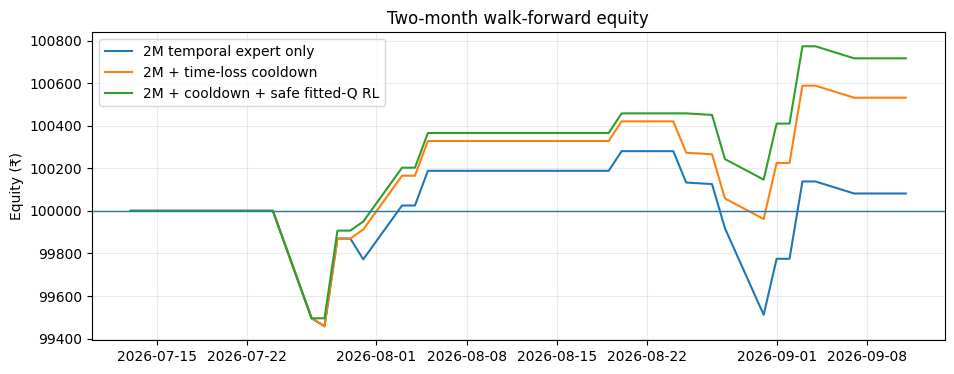

Saved:
C:\Users\Aadya Gupta\Desktop\Capstone\code_hmm\hmm_v14_two_month_walkforward_trades.csv
C:\Users\Aadya Gupta\Desktop\Capstone\code_hmm\hmm_v14_strict80_20_trades.csv
C:\Users\Aadya Gupta\Desktop\Capstone\code_hmm\hmm_v14_policy_summary.csv


In [5]:

two_month_daily, two_month_returns, two_month_equity = result_cache[
    "2M + cooldown + safe fitted-Q RL"
]

rng = np.random.default_rng(42)
boot_sharpes = []

for _ in range(5000):
    sample = rng.choice(
        two_month_returns.values,
        size=len(two_month_returns),
        replace=True,
    )
    std = np.std(sample, ddof=1)
    if std > 1e-12:
        boot_sharpes.append(
            np.sqrt(252) * np.mean(sample) / std
        )

ci = np.percentile(boot_sharpes, [2.5, 50, 97.5])

print("Two-month Sharpe:", round(summary_table.loc[2, "daily_sharpe"], 3))
print("Bootstrap 95% Sharpe interval:", np.round(ci, 3))
print("Dated sessions:", len(two_month_returns))
print("Active trade days:", int((two_month_daily != 0).sum()))

display(
    two_month_safe_rl[
        [
            "timestamp", "entry_time", "week_of_month",
            "action_contracts", "reason",
            "net_pnl_rupees", "bars_held",
            "execution_and_hedge_cost",
            "hedge_payout", "equity",
        ]
    ].round(2)
)

traded = two_month_safe_rl[
    two_month_safe_rl["action_contracts"] > 0
].copy()

slot_performance = (
    traded.groupby("entry_time")
    .agg(
        trades=("net_pnl_rupees", "size"),
        net_pnl_rupees=("net_pnl_rupees", "sum"),
        average_trade=("net_pnl_rupees", "mean"),
        win_rate=("net_pnl_rupees", lambda s: (s > 0).mean()),
    )
    .sort_values("net_pnl_rupees")
)

display(slot_performance.round(3))

print("Decision reasons:")
print(two_month_safe_rl["reason"].value_counts())

fig, ax = plt.subplots(figsize=(11, 4))

for label in [
    "2M temporal expert only",
    "2M + time-loss cooldown",
    "2M + cooldown + safe fitted-Q RL",
]:
    _, _, equity = result_cache[label]
    ax.plot(equity.index, equity.values, label=label)

ax.axhline(INITIAL_CAPITAL, linewidth=1)
ax.set_title("Two-month walk-forward equity")
ax.set_ylabel("Equity (₹)")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

OUT_2M = Path("C:/Users/Aadya Gupta/Desktop/Capstone/code_hmm/hmm_v14_two_month_walkforward_trades.csv")
OUT_80 = Path("C:/Users/Aadya Gupta/Desktop/Capstone/code_hmm/hmm_v14_strict80_20_trades.csv")
OUT_SUMMARY = Path("C:/Users/Aadya Gupta/Desktop/Capstone/code_hmm/hmm_v14_policy_summary.csv")

two_month_safe_rl.to_csv(OUT_2M, index=False)
strict_80_safe_rl.to_csv(OUT_80, index=False)
summary_table.to_csv(OUT_SUMMARY, index=False)

print("Saved:")
print(OUT_2M)
print(OUT_80)
print(OUT_SUMMARY)



## Reading the result

The policy now explicitly learns that **time itself can be a risk feature**.

A large loss at an entry slot can trigger a local cooldown, so a bad 14:00 trade does not need to be repeated at 14:00 immediately afterward.

The fitted-Q controller also sees weekday, week-of-month, day-of-month, month-cycle and historical bucket performance. As more months accumulate, these calendar effects become more statistically useful.

The mandatory hedge remains separate from this logic:

- hedge = emergency tail protection;
- thesis-break = exit a failing thesis;
- time-memory = stop repeating historically bad entry times;
- safe fitted-Q = veto/downsize only when there is enough evidence.

### Evaluation warning

This six-month file has now been used repeatedly for policy development. The July–September two-month result is useful for diagnosis and architecture selection, but should not be called a pristine final test anymore.

Freeze V14 and test it on new future days before treating its Sharpe or P&L as a production estimate.
